# Simulating hyperspectral RI measurements

This tutorial uses pyHyperRI package APIs directly to create a small synthetic hyperspectral measurement experiment. We reuse the 3C 353 sampling pattern from {repo-tree}`data/3c353_sim_vla_meas_hs/msSpecs.mat <data/3c353_sim_vla_meas_hs/msSpecs.mat>`, generate a three-channel hyperspectral image cube with {func}`hyri.interface.sim_hs_img_cube.gen_img_cube`, simulate visibilities with {class}`hyri.measurement_operator.meas_op_hs.MeasOpHyperspectral`, save the noisy data in pyHyperRI's measurement-directory format, and reload it with {func}`hyri.interface.load_data.load_data_to_tensor`.


## What this notebook covers

By the end of the notebook, you should have seen how to:

- generate a synthetic hyperspectral image cube from a reference image with {func}`hyri.interface.sim_hs_img_cube.gen_img_cube`;
- create a {class}`hyri.measurement_operator.meas_op_hs.MeasOpHyperspectral` instance directly from loaded sampling tensors;
- use {class}`hyri.measurement_operator.meas_op_nufft_finufft.MeasOpFinufft` as the channel-wise operators;
- simulate and save a pyHyperRI-compatible measurement;
- load the simulatedmeasurement with {func}`hyri.interface.load_data.load_data_to_tensor`;
- use the measurement operator to form dirty images and PSFs.


## Setup

This notebook assumes it is run from `docs/tutorials/` and that pyHyperRI has already been installed in the active Python environment.

The simulation is configured to run on CPU with double precision. Generated measurement files are written to `data/sim_meas_tutorial/`, leaving the repository example data untouched.

If pyHyperRI is not installed yet, follow the [Installation](../installation) guide first.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from astropy.io import fits
from scipy.io import savemat

from hyri.interface import gen_img_cube, load_data_to_tensor, load_mat_to_np
from hyri.measurement_operator import MeasOpFinufft, MeasOpHyperspectral

NOTEBOOK_DIR = Path.cwd()
ROOT = (NOTEBOOK_DIR / ".." / "..").resolve()
DATA_DIR = ROOT / "data" / "3c353_sim_vla_meas_hs"
TARGET_DIR = ROOT / "data" / "sim_meas_tutorial"

NUM_CH = 3
IMG_SIZE = (512, 512)
SUPER_RESOLUTION = 1.5
DEVICE = torch.device("cpu")
DTYPE = torch.float64

print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Repository root:    {ROOT}")
print(f"Example data:       {DATA_DIR}")
print(f"Target folder:      {TARGET_DIR}")
print(f"PyTorch:            {torch.__version__}")
print(f"Device:             {DEVICE}")
print(f"Torch dtype:        {DTYPE}")


Notebook directory: /mnt/py-hyper-ri/docs/tutorials
Repository root:    /mnt/py-hyper-ri
Example data:       /mnt/py-hyper-ri/data/3c353_sim_vla_meas_hs
Target folder:      /mnt/py-hyper-ri/data/sim_meas_tutorial
PyTorch:            2.10.0+cu128
Device:             cpu
Torch dtype:        torch.float64


## Inspect the example sampling pattern

A pyHyperRI measurement directory contains one `msSpecs.mat` metadata file and, when visibilities or channel-specific metadata are available, one `data_ch_<index>.mat` file per physical channel. Here we only reuse the stored `uvw` coordinates from the repository example. Sampling patterns can also be generated externally, for example with CASA [`simobserve`](https://casadocs.readthedocs.io/en/stable/api/tt/casatasks.simulation.simobserve.html).


In [2]:
ms_specs = load_mat_to_np(str(DATA_DIR / "msSpecs.mat"))
uvw_raw = np.asarray(ms_specs["uvw"]).squeeze()
uvw = uvw_raw.T if uvw_raw.shape[0] == 3 else uvw_raw

print(f"Stored uvw shape:      {uvw_raw.shape}")
print(f"Working uvw shape:     {uvw.shape}")
print(f"Number of samples:     {uvw.shape[0]:,}")

Stored uvw shape:      (3, 1652157)
Working uvw shape:     (1652157, 3)
Number of samples:     1,652,157


## Define and save a new `msSpecs.mat`

The simulated data use observation frequencies uniformly spaced between 1 and 2 GHz. The new metadata file is written to `TARGET_DIR`, and old notebook-generated channel files in that folder are cleared before the first loader call to avoid reusing stale visibilities. The original example data are left untouched.


In [3]:
TARGET_DIR.mkdir(parents=True, exist_ok=True)

for old_file in TARGET_DIR.glob("data_ch_*.mat"):
    old_file.unlink()

freqs = np.linspace(1.0e9, 2.0e9, NUM_CH, dtype=np.float64)
weights_nat = np.ones(uvw.shape[0], dtype=np.float64)

savemat(
    TARGET_DIR / "msSpecs.mat",
    {
        "uvw": uvw_raw,
        "freqs": freqs.reshape(1, -1),
    },
)

print("Simulated channel frequencies [GHz]:", freqs / 1e9)
print(f"Wrote measurement metadata to {TARGET_DIR}")


Simulated channel frequencies [GHz]: [1.  1.5 2. ]
Wrote measurement metadata to /mnt/py-hyper-ri/data/sim_meas_tutorial


## Generate a synthetic hyperspectral sky cube

The helper {func}`hyri.interface.sim_hs_img_cube.gen_img_cube` creates a spatially varying power-law model with curvature,

$$
\boldsymbol{x}_\nu = \boldsymbol{x}_{\nu_0}\left(\frac{\nu}{\nu_0}\right)^{\boldsymbol{\alpha} + \boldsymbol{\beta}\log(\nu / \nu_0)},
$$

where the first selected frequency is the reference frequency $\nu_0$. The spectral-index and curvature maps are simulated with the stationary Gaussian-process method following Thouvenin et al. (2023). We use the first channel of the repository `groundtruth.fits` cube as the reference image.

The image cube is displayed in logarithmic scale using the same mapping as the uSARA and AIRI tutorials,

$$
\operatorname{rlog}(\boldsymbol{x}) = x_{\max} \log_a\left(\frac{a}{x_{\max}}\boldsymbol{x} + 1\right).
$$

The maximum intensity $x_{\max}$ is set to $1$, and the lgarithmic factor $a$ is set to the approximate dynamic range $10^4$. The spectral-index and curvature maps are displayed in linear scale.


In [4]:
groundtruth = np.asarray(fits.getdata(DATA_DIR / "groundtruth.fits"), dtype=np.float64)
reference_image = groundtruth[0]

np.random.seed(42)
img_cube_np, spectral_index, curvature = gen_img_cube(
    reference_image,
    freqs,
    sig_blur=10,
    sig_gauss_field=10,
    curv_scale=0.5,
)
img_cube_np = np.asarray(img_cube_np, dtype=np.float64)
img_cube = torch.as_tensor(img_cube_np, dtype=DTYPE, device=DEVICE).unsqueeze(0)

print(f"Reference image shape: {reference_image.shape}")
print(f"Sky cube tensor shape: {tuple(img_cube.shape)}")
print(f"Spectral index range: [{spectral_index.min():.3f}, {spectral_index.max():.3f}]")
print(f"Curvature range:      [{curvature.min():.3f}, {curvature.max():.3f}]")

Reference image shape: (512, 512)
Sky cube tensor shape: (1, 3, 512, 512)
Spectral index range: [-5.000, 0.000]
Curvature range:      [-0.500, 0.486]


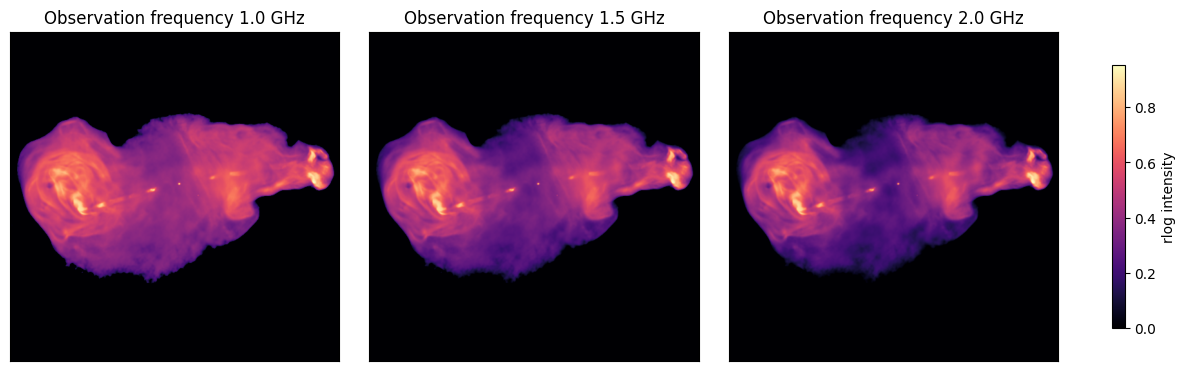

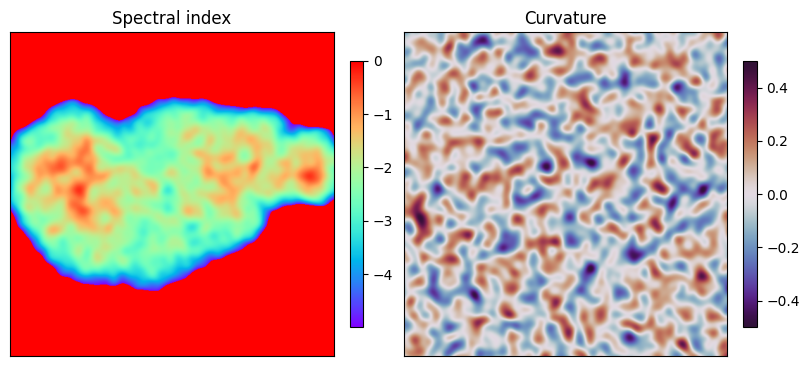

In [5]:
def imshow_panel(ax, image, title, cmap="magma", symmetric=False):
    image = np.asarray(image)
    if symmetric:
        vmax = np.nanmax(np.abs(image))
        vmin = -vmax
    else:
        vmin = np.nanmin(image)
        vmax = np.nanmax(image)
    im = ax.imshow(image, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


def rlog(x, a, x_max=1.0):
    return x_max * np.log10(a * x / x_max + 1.0) / np.log10(a)


dynamic_range = 1e4
img_cube_log = rlog(np.clip(img_cube_np, 0.0, None), dynamic_range)

fig, axes = plt.subplots(1, NUM_CH, figsize=(12, 3.6), constrained_layout=True)
for ch, ax in enumerate(axes):
    im = imshow_panel(
        ax,
        img_cube_log[ch],
        f"Observation frequency {freqs[ch] / 1e9:.1f} GHz",
        cmap="magma",
    )
fig.colorbar(im, ax=axes, shrink=0.8, label="rlog intensity")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), constrained_layout=True)
im0 = imshow_panel(axes[0], spectral_index, "Spectral index", cmap="rainbow")
im1 = imshow_panel(axes[1], curvature, "Curvature", cmap="twilight_shifted", symmetric=True)
fig.colorbar(im0, ax=axes[0], shrink=0.8)
fig.colorbar(im1, ax=axes[1], shrink=0.8)
plt.show()


## Load sampling tensors and build the hyperspectral operator

{func}`hyri.interface.load_data.load_data_to_tensor` sets the image pixel size according to the super-resolution factor or the user input, converts the `uvw` sampling pattern into the normalised coordinates used by the NUFFT operators, and returns one tensor per effective channel. We use natural weighting only for simplicity. Imaging weights can be generated by enabling the `data_weighting` flag.

The hyperspectral operator is constructed with {class}`hyri.measurement_operator.meas_op_hs.MeasOpHyperspectral`, using {class}`hyri.measurement_operator.meas_op_nufft_finufft.MeasOpFinufft` as the monochromatic measurement operator for each channel.


In [6]:
data = load_data_to_tensor(
    str(TARGET_DIR),
    super_resolution=SUPER_RESOLUTION,
    data_weighting=False,
    load_weight=False,
    img_size=IMG_SIZE,
    dtype=DTYPE,
    device=DEVICE,
    ch_start=1,
    ch_last=NUM_CH,
    ch_effctive=NUM_CH,
    verbose=True,
)

meas_op = MeasOpHyperspectral(
    u=data["u"],
    v=data["v"],
    img_size=IMG_SIZE,
    natural_weight=data["natural_weight"],
    image_weight=data["imaging_weight"],
    precond_weight=data["precond_weight"],
    meas_op_class=MeasOpFinufft,
    device=DEVICE,
    dtype=DTYPE,
    verbose=False,
)

print(f"Loaded frequencies tensor: {tuple(data['freqs'].shape)}")
print(f"Image pixel size:          {data['image_pixel_size']:.4g} arcsec")
for ch, u_ch in enumerate(data["u"], start=1):
    print(f"channel {ch}: u/v tensor shape {tuple(u_ch.shape)}")

INFO: loading sampling pattern from /mnt/py-hyper-ri/data/sim_meas_tutorial
INFO: loading data from physical channel 1 to 3 with 3 effective channels. 
INFO: rank 0 loading physical channels from 1 to 3, corresponding to effective channels from 1 to 3.
INFO: no uvw flag found, all points are considered valid.
INFO: default pixelsize: 0.2814 arcsec, that is 1.500 x nominal resolution.
INFO: imaging weights will not be applied.
INFO: preconditioning weights will not be generated.
INFO: effective channel 1 loaded 1652157 uv points, frequency 1.000e+09 Hz.
INFO: effective channel 2 loaded 1652157 uv points, frequency 1.500e+09 Hz.
INFO: effective channel 3 loaded 1652157 uv points, frequency 2.000e+09 Hz.
INFO: data loading completed.
Loaded frequencies tensor: (1, 3, 1, 1)
Image pixel size:          0.2814 arcsec
channel 1: u/v tensor shape (1, 1, 1652157)
channel 2: u/v tensor shape (1, 1, 1652157)
channel 3: u/v tensor shape (1, 1, 1652157)


The loader converts the physical $uv$ coordinates into the normalised Fourier coordinates used by the NUFFT backend, namely the range $[-\pi, \pi]$. One can notice the frequency-dependent scaling of the sampling pattern across spectral channels.

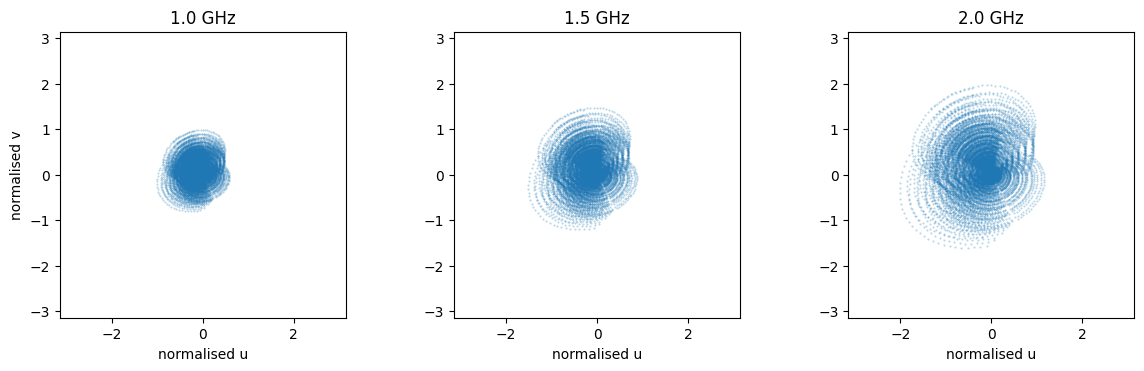

In [7]:
stride = max(1, data["u"][0].numel() // 20_000)

fig, axes = plt.subplots(1, NUM_CH, figsize=(12, 3.6), constrained_layout=True)
for ch, ax in enumerate(axes):
    u_plot = data["u"][ch].detach().cpu().view(-1).numpy()
    v_plot = data["v"][ch].detach().cpu().view(-1).numpy()
    ax.scatter(u_plot[::stride], v_plot[::stride], s=0.2, alpha=0.35, rasterized=True)
    ax.set_title(f"{freqs[ch] / 1e9:.1f} GHz")
    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim(-np.pi, np.pi)
    ax.set_aspect("equal")
    ax.set_xlabel("normalised u")
axes[0].set_ylabel("normalised v")
plt.show()


## Simulate noiseless visibilities

The radio-interferometric linear sensing model can be written as

$$
\boldsymbol{y} = \boldsymbol{\Phi}\boldsymbol{x} + \boldsymbol{n},
$$

where $\boldsymbol{x}$ is the sky image cube, $\boldsymbol{\Phi}$ is the hyperspectral measurement operator, and $\boldsymbol{n}$ is complex Gaussian visibility noise. In this step we first generate the noiseless visibilities $\boldsymbol{\Phi}\boldsymbol{x}$ with {meth}`hyri.measurement_operator.meas_op_hs.MeasOpHyperspectral.forward_op`.

The input image tensor has shape `(1, num_channels, height, width)`, and the returned visibilities are organised as a tuple of tensors, one per channel, with shape `(1, 1, num_vis)`. The number of visibilities can differ between channels when flags or observing settings vary by channel.


In [8]:
with torch.no_grad():
    y_sim = meas_op.forward_op(img_cube)

for ch, y_ch in enumerate(y_sim, start=1):
    print(
        f"channel {ch}: shape={tuple(y_ch.shape)}, dtype={y_ch.dtype}, "
    )

channel 1: shape=(1, 1, 1652157), dtype=torch.complex128, 
channel 2: shape=(1, 1, 1652157), dtype=torch.complex128, 
channel 3: shape=(1, 1, 1652157), dtype=torch.complex128, 


## Add controlled complex Gaussian noise

Terris et al. (2023) proposed linking the visibility-domain noise level $\tau$ and the image-domain noise level $\sigma$ as

$$
\sigma = \frac{\tau}{\sqrt{2L}}, \qquad L = \|\boldsymbol{\Phi}^\dagger\boldsymbol{\Phi}\|_S,
$$

where $L$ is the channel-wise normal-operator norm. Here we use this equation to determine $\tau$ with $\sigma = 10^{-4}$, approximately the inverse dynamic range of the reference image.

In [9]:
SIGMA_IMAGE = 1.0e-4
NOISE_SEED = 43

op_norm_ch = meas_op.get_op_norm_ch(
    compute_flag=True,
    rel_tol=5e-4,
    max_iter=50,
    verbose=False,
)
last_channel_norm = op_norm_ch[0, -1, 0, 0]
tau = SIGMA_IMAGE * torch.sqrt(2.0 * last_channel_norm)

rng = torch.Generator(device=DEVICE)
rng.manual_seed(NOISE_SEED)

y_noisy = []
for y_ch in y_sim:
    noise_real = torch.randn(y_ch.shape, generator=rng, device=DEVICE, dtype=DTYPE)
    noise_imag = torch.randn(y_ch.shape, generator=rng, device=DEVICE, dtype=DTYPE)
    noise = (tau / np.sqrt(2.0)) * torch.complex(noise_real, noise_imag)
    y_noisy.append(y_ch + noise)
y_noisy = tuple(y_noisy)

print("Channel-wise L estimates:", op_norm_ch.detach().cpu().view(-1).numpy())
print(f"target sigma = {SIGMA_IMAGE:.2e}")
print(f"tau from last channel = {tau.item():.3e}")

Channel-wise L estimates: [1.11897146e+10 5.56147551e+09 3.30899049e+09]
target sigma = 1.00e-04
tau from last channel = 8.135e+00


## Save the simulated measurement directory

Only the noisy visibilities are saved to the channel files. Each channel file contains complex `data_I` and vector-valued `weightsNat` set to one. No `flag` array is written, so the loader treats all samples as valid by default. The synthetic ground-truth cube is saved beside the measurement files for later inspection.

In [10]:
for ch, y_ch in enumerate(y_noisy, start=1):
    savemat(
        TARGET_DIR / f"data_ch_{ch}.mat",
        {
            "data_I": y_ch.detach().cpu().numpy().reshape(-1),
            "weightsNat": weights_nat,
        },
    )

fits.writeto(
    TARGET_DIR / "groundtruth_sim.fits", 
    img_cube_np.astype(np.float32), 
    overwrite=True
)

print(f"Saved noisy simulated visibilities to {TARGET_DIR}")
print("Saved synthetic image cube as groundtruth_sim.fits")

Saved noisy simulated visibilities to /mnt/py-hyper-ri/data/sim_meas_tutorial
Saved synthetic image cube as groundtruth_sim.fits


## Reload the simulated data

This final load uses the same public loader as the imaging examples. It confirms that the saved folder follows pyHyperRI's expected measurement-directory layout.

In [11]:
reloaded = load_data_to_tensor(
    str(TARGET_DIR),
    super_resolution=SUPER_RESOLUTION,
    data_weighting=False,
    load_weight=False,
    img_size=IMG_SIZE,
    dtype=DTYPE,
    device=DEVICE,
    ch_start=1,
    ch_last=NUM_CH,
    ch_effctive=NUM_CH,
    verbose=True,
)

meas_op_reloaded = MeasOpHyperspectral(
    u=reloaded["u"],
    v=reloaded["v"],
    img_size=IMG_SIZE,
    natural_weight=reloaded["natural_weight"],
    image_weight=reloaded["imaging_weight"],
    precond_weight=reloaded["precond_weight"],
    meas_op_class=MeasOpFinufft,
    device=DEVICE,
    dtype=DTYPE,
    verbose=False,
)

for ch, y_ch in enumerate(reloaded["y"], start=1):
    print(f"reloaded channel {ch}: y shape {tuple(y_ch.shape)}, dtype {y_ch.dtype}")


INFO: loading sampling pattern from /mnt/py-hyper-ri/data/sim_meas_tutorial
INFO: loading data from physical channel 1 to 3 with 3 effective channels. 
INFO: rank 0 loading physical channels from 1 to 3, corresponding to effective channels from 1 to 3.
INFO: no uvw flag found, all points are considered valid.
INFO: default pixelsize: 0.2814 arcsec, that is 1.500 x nominal resolution.
INFO: imaging weights will not be applied.
INFO: preconditioning weights will not be generated.
INFO: effective channel 1 loaded 1652157 uv points, frequency 1.000e+09 Hz.
INFO: effective channel 2 loaded 1652157 uv points, frequency 1.500e+09 Hz.
INFO: effective channel 3 loaded 1652157 uv points, frequency 2.000e+09 Hz.
INFO: data loading completed.
reloaded channel 1: y shape (1, 1, 1652157), dtype torch.complex128
reloaded channel 2: y shape (1, 1, 1652157), dtype torch.complex128
reloaded channel 3: y shape (1, 1, 1652157), dtype torch.complex128


## Dirty images and PSFs

After reloading, we can apply the adjoint operator to inspect the dirty images and the point spread functions (PSFs). The dirty image is defined as $\mathrm{Re} \{ \boldsymbol{\Phi}^\dagger \boldsymbol{y} \}$, while the PSF is the response of the forward and adjoint operators to a Dirac impulse image $\boldsymbol{\delta}$, i.e. $\mathrm{Re} \{ \boldsymbol{\Phi}^\dagger \boldsymbol{\Phi} \boldsymbol{\delta} \}$. Both are shown in linear scale with their native value ranges.


In [12]:
with torch.no_grad():
    dirty_reloaded = meas_op_reloaded.adjoint_op(reloaded["y"])
    psf_reloaded = meas_op_reloaded.get_psf()

dirty_reloaded_np = dirty_reloaded.squeeze(0).detach().cpu().numpy()
psf_reloaded_np = psf_reloaded.squeeze(0).detach().cpu().numpy()

print(f"Reloaded dirty cube: {dirty_reloaded_np.shape}")
print(f"PSF cube:            {psf_reloaded_np.shape}")


Reloaded dirty cube: (3, 512, 512)
PSF cube:            (3, 512, 512)


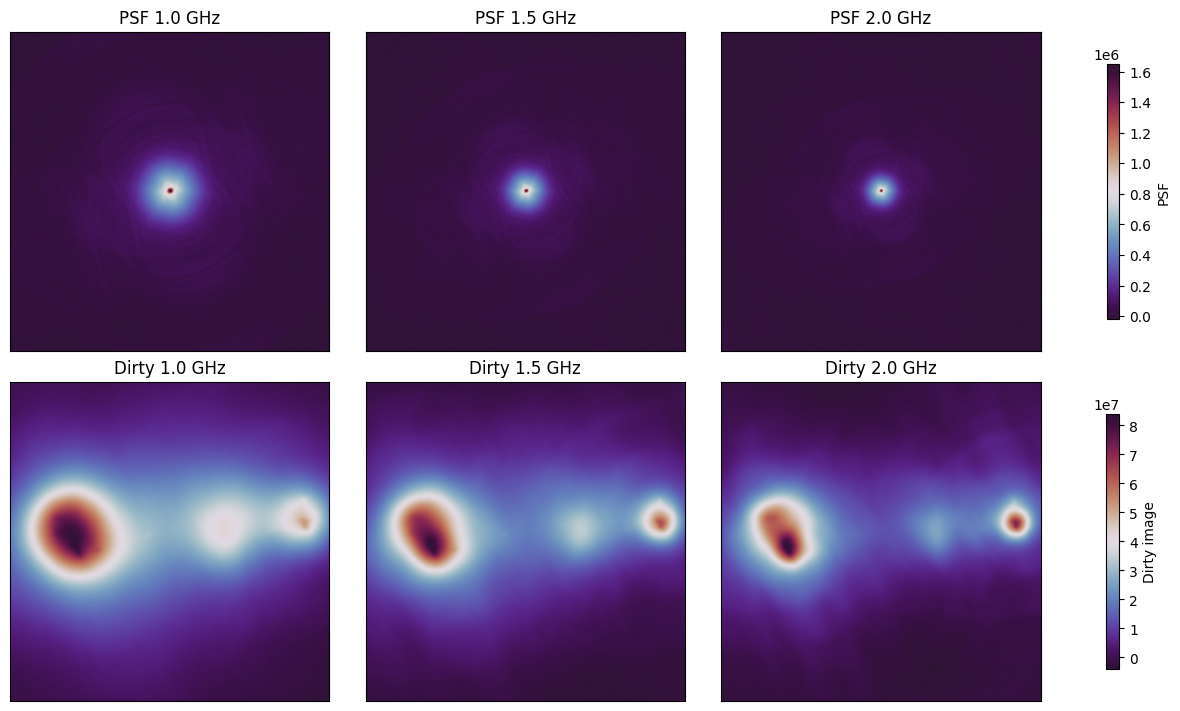

In [13]:
fig, axes = plt.subplots(2, NUM_CH, figsize=(12, 7.0), constrained_layout=True)
for ch in range(NUM_CH):
    im0 = imshow_panel(
        axes[0, ch],
        psf_reloaded_np[ch],
        f"PSF {freqs[ch] / 1e9:.1f} GHz",
        cmap="twilight_shifted",
    )
    im1 = imshow_panel(
        axes[1, ch],
        dirty_reloaded_np[ch],
        f"Dirty {freqs[ch] / 1e9:.1f} GHz",
        cmap="twilight_shifted",
    )
fig.colorbar(im0, ax=axes[0, :], shrink=0.8, label="PSF")
fig.colorbar(im1, ax=axes[1, :], shrink=0.8, label="Dirty image")
plt.show()


## Takeaways

pyHyperRI adopts a modular design: measurement operators, data-loading utilities, and simulation helpers can be reused in customised workflows. This makes the package useful for simulation, benchmarking, and method development, as well as for end-to-end image reconstruction.

## References

- Terris, M., Dabbech, A., Tang, C., & Wiaux, Y. (2023). [Image reconstruction algorithms in radio interferometry: From handcrafted to learned regularization denoisers](https://doi.org/10.1093/mnras/stac2672). *MNRAS*, 518(1), 604-622.
- Thouvenin, P.-A., Abdulaziz, A., Dabbech, A., Repetti, A., & Wiaux, Y. (2023). [Parallel faceted imaging in radio interferometry via proximal splitting (Faceted HyperSARA): I. Algorithm and simulations](https://doi.org/10.1093/mnras/stac1521). *MNRAS*, 521(1), 1-19.